In [1109]:
from typing import Callable

import duckdb
import numpy as np
from numpy.typing import ArrayLike
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator
from sklearn.metrics import root_mean_squared_error, mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import check_X_y, check_array
from scipy.sparse import csr_array, issparse

from recommender import recommender_scorer

In [ ]:
def _predict_y_fm(X, intercept, weights, factors):
    X_dot_factors = X @ factors
    X_dot_factors_squares = X ** 2 @ (factors ** 2)
    interactions = np.sum(X_dot_factors ** 2 - X_dot_factors_squares, axis=1) / 2
    linear_part = X @ weights
    return intercept + linear_part + interactions, X_dot_factors


class FactorizationMachine(BaseEstimator):
    def __init__(
            self, 
            factors_num: int = 1, 
            max_iter=300,
            tol=1e-4,
            learn_rate=0.01,
            loss: str | Callable[[ArrayLike, ArrayLike], float] = "mse",
            dloss_dpred: Callable[[ArrayLike, ArrayLike], ArrayLike] | None = None,
            weights_penalty=0.00001,
            factors_penalty=0.001,
            batch_size=1000,
            patience=3,
            random_state=None,
            verbose: bool = False,
    ):
        self.factors_num = factors_num
        self.max_iter = max_iter
        self.tol = tol
        self.learn_rate = learn_rate
        if loss == "mse":
            self.loss = lambda y, y_pred: np.mean((y - y_pred) ** 2)
            self.dloss_dpred = lambda y, y_pred: 2 * (y_pred - y) / y.shape[0]
        else:
            self.loss = loss
            self.dloss_dpred = dloss_dpred

        self.patience = patience
        self.batch_size = batch_size
        self.random_state = random_state
        self.weights_penalty = weights_penalty
        self.factors_penalty = factors_penalty
        self.verbose = verbose

    def fit(
        self,
        X: ArrayLike,
        y: ArrayLike,
        eval_set: tuple[ArrayLike, ArrayLike] | None = None,
    ):
        X, y = check_X_y(X, y, accept_sparse=["csr"])
        if issparse(X):
            X = csr_array(X)
        n_samples, dim = X.shape
        rng = np.random.default_rng(seed=self.random_state)
        self._intercept = np.mean(y)
        self._weights = np.zeros(shape=(dim,), dtype=float)
        self._factors = rng.normal(scale=0.01, size=(dim, self.factors_num))
        no_improvement_count = 0
        best_val_score = -np.inf

        for iter in range(self.max_iter):
            permutation = rng.permutation(n_samples)

            for i in range(0, n_samples, self.batch_size):
                batch_indices = permutation[i : i + self.batch_size]
                X_batch = X[batch_indices]
                y_batch = y[batch_indices]
                y_pred_batch, X_dot_factors = self._predict(X_batch)

                dloss_dpred = self.dloss_dpred(y_batch, y_pred_batch)
                self._intercept -= self.learn_rate * np.sum(dloss_dpred)
                self._weights -= self.learn_rate * (
                    X_batch.T @ dloss_dpred
                    + 2 * self.weights_penalty * self._weights
                )
                factor_coef_0 = X_batch.T @ (dloss_dpred[:, np.newaxis] * X_dot_factors)
                factor_coef_1 = -(X_batch.T ** 2) @ dloss_dpred
                self._factors -= self.learn_rate * (
                    factor_coef_0 + factor_coef_1[:, np.newaxis] * self._factors
                    + 2 * self.factors_penalty * self._factors
                )
            y_pred = self._predict(X)[0]
            curr_loss = self.loss(y_pred, y)

            if eval_set is None:
                if  iter > 0 and abs(curr_loss - prev_loss) < self.tol:
                    no_improvement_count += 1
                else:
                    no_improvement_count = 0
                prev_loss = curr_loss

            else:
                val_score = self.score(eval_set[0], eval_set[1])
                if val_score > best_val_score + self.tol:
                    best_val_score = val_score
                    no_improvement_count = 0
                else:
                    no_improvement_count += 1

            if no_improvement_count >= self.patience:
                self.fitted_ = True
                self.n_iter = iter
                return self


            if self.verbose == True and iter % 50 == 0:
                print(
                    f"Iteration {iter}, factors num {self.factors_num}, "
                    f"intercept {self._intercept}, loss {curr_loss}"
                )


        self.n_iter = self.max_iter
        self.fitted_ = True
        return self
    
    def _predict(self, X):
        return _predict_y_fm(X, self._intercept, self._weights, self._factors)

    def predict(self, X):
        X = check_array(X, accept_sparse=["csr"])
        if issparse(X):
            X = csr_array(X)
        return self._predict(X)[0]

    def score(self, X, y):
        y_pred = self._predict(X)[0]
        return -root_mean_squared_error(y, y_pred)



In [1111]:
rng = np.random.default_rng()
toy_shape = (1000, 10)
X = rng.normal(size=toy_shape)

intercept = -100
weights = np.ones(shape=(X.shape[1],))
factors = rng.normal(size=(X.shape[1], 4))

y = _predict_y_fm(X, intercept, weights, factors)[0]
y += rng.normal(scale=abs(y.mean()) * 0.05)

In [1112]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, train_size=0.5)

fm = GridSearchCV(
    estimator=FactorizationMachine(max_iter=300, random_state=42, batch_size=300),
    param_grid={
        "factors_num": [1, 3, 4, 5, 10],
    }
)

fm.fit(X_train, y_train, eval_set=(X_val, y_val))

,estimator,Factorization...ndom_state=42)
,param_grid,"{'factors_num': [1, 3, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,factors_num,10


In [1113]:
fm.best_params_

{'factors_num': 10}

In [1114]:
fm.score(X_test, y_test)

-1.6162287672074631

<Axes: >

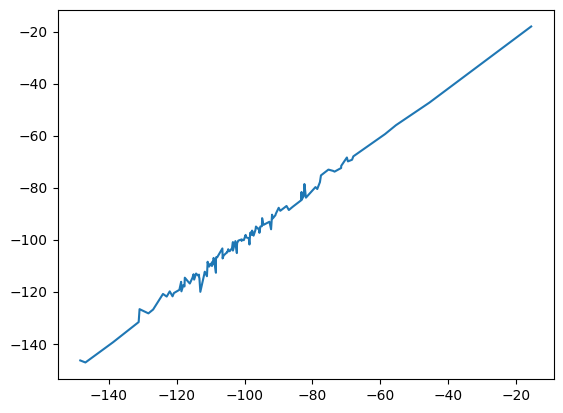

In [1115]:
y_pred = fm.predict(X_test)

sns.lineplot(x=y_test, y=y_pred)

## Movies dataset

MovieLens100k and MovieLens1M can't be used together -- users' ids don't match.

In [1116]:
with duckdb.connect("/home/maria-khanina/mkgit/movies_project/data/database.duckdb", read_only=True) as db_conn:
    ratings_df = db_conn.execute("""
        SELECT *
        FROM ratings INNER JOIN movies USING (movie_id)
    """).df()


In [1117]:
ratings_df.head()

,user_id,movie_id,rating,timestamp,title,genres
0,1945,1248,3,974692298,Touch of Evil (1958),Crime|Film-Noir|Thriller
1,1945,1252,3,974691937,Chinatown (1974),Film-Noir|Mystery|Thriller
2,1945,589,3,974692787,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller
3,1945,6,3,974693183,Heat (1995),Action|Crime|Thriller
4,1945,1267,2,974692090,"Manchurian Candidate, The (1962)",Film-Noir|Thriller


In [1118]:
ratings_df.shape

(1000209, 6)

In [1119]:
ratings_df.isna().sum()

user_id      0
movie_id     0
rating       0
timestamp    0
title        0
genres       0
dtype: int64

In [1120]:
ratings_df["rating"].value_counts().sort_index()

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

In [1121]:
X = ratings_df[["user_id", "movie_id"]]
y = ratings_df["rating"]

In [1122]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.01,
    random_state=42,
)

In [1123]:
X_val, X_test, y_val, y_test = train_test_split(
    X_test, y_test,
    test_size=0.5,
    random_state=42,
)

### Average train rating as prediction

In [1124]:
df_train = pd.concat((X_train, y_train), axis="columns")
avg_train_ratings = df_train.groupby("movie_id", as_index=False)["rating"].mean()
avg_train_ratings.columns = ["movie_id", "avg_movie_rating"]
df_train = pd.merge(left=df_train, right=avg_train_ratings, on="movie_id")

In [1125]:
df_val = pd.merge(left=X_val, right=avg_train_ratings, on="movie_id", how="left")
df_val.isna().sum()

user_id             0
movie_id            0
avg_movie_rating    0
dtype: int64

In [1126]:
root_mean_squared_error(y_val, df_val["avg_movie_rating"])

0.9710501169781921

### Factorization Machine with only encoded user_id and movie_id as features

In [1127]:
all_users = np.sort(X_train["user_id"].unique())
all_movies = np.sort(X_train["movie_id"].unique())

In [1128]:
base_fm = Pipeline(
    steps=[
        ("encode", OneHotEncoder(
            categories=[all_users, all_movies],
            handle_unknown="ignore",
        )),
        ("predict", FactorizationMachine(
            factors_num=20,
            weights_penalty=0.0001,
            factors_penalty=0.01,
            batch_size=1000, 
            verbose=True,
        ))
    ]
)

In [1129]:
base_fm.fit(X_train, y_train)
y_pred = base_fm.predict(X_val)
root_mean_squared_error(y_val, y_pred)

Iteration 0, factors num 20, intercept 3.581128218899214, loss 1.237025193510858


KeyboardInterrupt: 

In [ ]:
base_search = GridSearchCV(
    estimator=base_fm,
    param_grid={
        "predict__factors_num": [5, 10, 20],
        "predict__weights_penalty": [0.0001],
        "predict__factors_penalty": [0.001, 0.01],
    },
    verbose=100,
)

In [ ]:
base_search.fit(X_train, y_train)

In [ ]:
y_pred = base_search.predict(X_val)

In [ ]:
root_mean_squared_error(y_val, y_pred)

np.float64(-0.9116375086505493)

In [ ]:
base_search.best_params_

{'predict__factors_num': 10, 'predict__weights_penalty': 0}

### Factorization Machine with user's preferences added to features

In [ ]:
all_grades_df = pd.pivot_table(
    data=pd.concat((X_train, y_train), axis="columns"),
    index="user_id",
    columns="movie_id",
    values="rating",
    fill_value=0,
)

all_grades_df.reset_index(level="user_id", inplace=True)

In [ ]:
class UserHistoryTransformer:
    def __init__(
            self, 
            user_col: str = "user_id", 
            item_col: str = "movie_id", 
            rating_col: str = "rating",
            fill_missing: float = 0.0,
    ):
        self._user_col = user_col
        self._item_col = item_col
        self._rating_col = rating_col
        self._fill_missing = fill_missing

    def fit(self, X, y):
        self._history_df = pd.pivot_table(
            data=pd.concat((X, y), axis="columns"),
            index=self._user_col,
            columns=self._item_col,
            values=self._rating_col,
            fill_value=self._fill_missing,
        )
    
    def transform(self, X):
        pass


In [ ]:
from sklearn.decomposition import NMF

matr_fact = NMF(init="nndsvd", verbose=100)

user_preferences = pd.pivot_table(
    data=pd.concat((X_train, y_train), axis="columns"),
    index="user_id",
    columns="movie_id",
    values="rating",
    fill_value=0,
)

for n_components in [10, 20, 30]:
    matr_fact.set_params(n_components=n_components)
    matr_fact.fit(user_preferences)
    